# Texture contrast

This notebook scores one measurement: how much the roughness of the luminance inside a known building changed between a pre-event satellite image and a post-event image. Roughness is the contrast of the gray-level co-occurrence matrix (GLCM), with 8 gray levels, at a distance of one pixel, averaged over 0°, 45°, 90°, and 135°. The score is the absolute difference of that contrast between the two dates. A higher score means the roof texture changed more.

The co-occurrence matrix and its contrast are the texture descriptors of Haralick, Shanmugam, and Dinstein (1973). In the course books they are in Pratt, *Digital Image Processing*, Section 16.2 (the second-order histogram and its "inertia", Eq. 16.2-15) and Section 16.6 (the co-occurrence matrix at 0°, 45°, 90°, and 135°, Eq. 16.6-6, and its mean over the angles, Eq. 16.6-7), and in the texture section of Gonzalez and Woods. Texture is Week 12 in the syllabus. The matrix is built here by counting pixel pairs, as Lab 1 counts a histogram, not by a library call.

The notebook does not read the other four scores and does not choose weights. Mexico City and Palu are not opened. Damage labels are joined only after the score exists, so the figures and the partial table can be drawn. The score function itself takes two quantized images, a mask, and a shift, and returns a number.

Two checks from the workflow plan are at the end: the count of buildings under 40 pixels, and the square-meter area formula on two images from the subset.

## Dataset and the shared subset

The xView2 challenge training set is `Dataset/train` next to the project folder that contains this notebook. `XVIEW2_ROOT` overrides that path. Each pair is a pre-event PNG, a post-event PNG, and a post-disaster JSON. Polygons come from `features.xy`: pixel coordinates in the WKT, `uid` as the building id, and `subtype` as the damage label. Unclassified polygons are dropped.

Results for this score are written under `outputs/texture_contrast/progress/`, with `tables/` for the CSV and `figures/` for the plots. `outputs/texture_contrast/final/` is left for the later pass over the remaining practice pairs.

The 13 pairs below are the same practice subset as the correlation-loss notebook, so the partial tables can be joined on `image_id` and `building_id`. This run is incomplete. It is not the evaluation.

In [1]:
import csv
import json
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np


def github_root():
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "texture_contrast.ipynb").is_file():
            return candidate
        nested = candidate / "Github"
        if (nested / "src" / "texture_contrast.ipynb").is_file():
            return nested
    raise FileNotFoundError("texture_contrast.ipynb")


GITHUB = github_root()
if os.environ.get("XVIEW2_ROOT"):
    DATA_ROOT = Path(os.environ["XVIEW2_ROOT"]).resolve()
else:
    DATA_ROOT = (GITHUB.parent / "Dataset" / "train").resolve()
IMAGE_DIR = DATA_ROOT / "images"
LABEL_DIR = DATA_ROOT / "labels"
SCORE_DIR = GITHUB / "outputs" / "texture_contrast"
TABLE_DIR = SCORE_DIR / "progress" / "tables"
FIGURE_DIR = SCORE_DIR / "progress" / "figures"
for folder in (
    TABLE_DIR,
    FIGURE_DIR,
    SCORE_DIR / "final" / "tables",
    SCORE_DIR / "final" / "figures",
):
    folder.mkdir(parents=True, exist_ok=True)

SUBSET = [
    "santa-rosa-wildfire_00000006",
    "santa-rosa-wildfire_00000007",
    "santa-rosa-wildfire_00000011",
    "santa-rosa-wildfire_00000002",
    "socal-fire_00000081",
    "socal-fire_00000082",
    "socal-fire_00000090",
    "socal-fire_00000002",
    "midwest-flooding_00000143",
    "midwest-flooding_00000001",
    "midwest-flooding_00000003",
    "guatemala-volcano_00000025",
    "guatemala-volcano_00000006",
]

if not IMAGE_DIR.is_dir() or not LABEL_DIR.is_dir():
    raise FileNotFoundError(DATA_ROOT)

## Shared preprocessing

The two cells below are the shared preprocessing, copied from the correlation-loss notebook without changes, so every score sees the same pixels.

The post-event image is histogram-matched to the pre-event image, channel by channel, with 256 bins. This is histogram specification from the point-processing lecture, built from the histogram and the cumulative distribution as in Lab 1. The shared code maps each post-event level to the smallest pre-event level whose cumulative value reaches it, which is the rule of Gonzalez and Woods; the lecture's worked example uses the closest cumulative value instead. Pixels that are very dark and locally smooth (luminance below 40 and a 5 by 5 local standard deviation below 8) are left out of both histograms. The local standard deviation comes from two 5 by 5 mean (box) filters, of the image and of its square, and the variance formula of the point-processing lecture. The lookup table is still applied to every pixel. This matters for texture: the match puts the two dates on one intensity scale, so the same 8 gray levels can be used on both.

Around a polygon whose short side is at least 12 pixels, the post-event patch is shifted by the peak of normalized cross-correlation, over at most 4 pixels. This is the template matching of Lab 3, Section 4. Smaller roofs, and roofs with a flat template, are left where they are. The polygon is then eroded with a 3 by 3 square, as in the binary-morphology lecture.

In [2]:
def luminance(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


def local_std(gray, window=5):
    values = gray.astype(np.float64)
    mean = cv2.blur(values, (window, window))
    second = cv2.blur(values * values, (window, window))
    variance = np.maximum(second - mean * mean, 0.0)
    return np.sqrt(variance)


def usable_pixels(image):
    gray = luminance(image)
    dark = gray < 40
    smooth = local_std(gray) < 8
    return ~(dark & smooth)


def match_channel(source, reference, source_keep, reference_keep):
    source_hist = np.bincount(source[source_keep], minlength=256).astype(np.float64)
    reference_hist = np.bincount(reference[reference_keep], minlength=256).astype(np.float64)
    if source_hist.sum() == 0 or reference_hist.sum() == 0:
        return source.copy()
    source_cdf = np.cumsum(source_hist) / source_hist.sum()
    reference_cdf = np.cumsum(reference_hist) / reference_hist.sum()
    lookup = np.searchsorted(reference_cdf, source_cdf, side="left")
    lookup = np.clip(lookup, 0, 255).astype(np.uint8)
    return lookup[source]


def histogram_match(post, pre):
    source_keep = usable_pixels(post)
    reference_keep = usable_pixels(pre)
    matched = np.empty_like(post)
    for channel in range(3):
        matched[:, :, channel] = match_channel(
            post[:, :, channel],
            pre[:, :, channel],
            source_keep,
            reference_keep,
        )
    return matched

In [3]:
def polygon_points(wkt):
    start = wkt.find("((")
    end = wkt.rfind("))")
    body = wkt[start + 2:end]
    points = []
    for piece in body.split(","):
        parts = piece.split()
        points.append([float(parts[0]), float(parts[1])])
    return np.asarray(points, dtype=np.float64)


def short_side(points):
    width = float(points[:, 0].max() - points[:, 0].min())
    height = float(points[:, 1].max() - points[:, 1].min())
    return min(width, height)


def best_shift(pre_gray, post_gray, points):
    if short_side(points) < 12:
        return 0, 0
    height, width = pre_gray.shape
    x0 = max(0, int(np.floor(points[:, 0].min())))
    y0 = max(0, int(np.floor(points[:, 1].min())))
    x1 = min(width, int(np.ceil(points[:, 0].max())) + 1)
    y1 = min(height, int(np.ceil(points[:, 1].max())) + 1)
    if x1 - x0 < 2 or y1 - y0 < 2:
        return 0, 0
    template = pre_gray[y0:y1, x0:x1]
    if float(template.std()) < 1.0:
        return 0, 0
    search_x0 = max(0, x0 - 4)
    search_y0 = max(0, y0 - 4)
    search_x1 = min(width, x1 + 4)
    search_y1 = min(height, y1 + 4)
    search = post_gray[search_y0:search_y1, search_x0:search_x1]
    if search.shape[0] < template.shape[0] or search.shape[1] < template.shape[1]:
        return 0, 0
    scores = cv2.matchTemplate(search, template, cv2.TM_CCOEFF_NORMED)
    if not np.isfinite(scores).any():
        return 0, 0
    scores = np.nan_to_num(scores, nan=-1.0)
    _, _, _, peak = cv2.minMaxLoc(scores)
    dx = int(np.clip(peak[0] - (x0 - search_x0), -4, 4))
    dy = int(np.clip(peak[1] - (y0 - search_y0), -4, 4))
    return dx, dy


def polygon_mask(points, shape):
    mask = np.zeros(shape, dtype=np.uint8)
    contour = np.round(points).astype(np.int32)
    cv2.fillPoly(mask, [contour], 1)
    return mask


def interior_mask(points, shape):
    mask = polygon_mask(points, shape)
    eroded = cv2.erode(mask, np.ones((3, 3), np.uint8), iterations=1)
    if int(eroded.sum()) < 40:
        return mask
    return eroded

## Gray levels, the co-occurrence matrix, and contrast

Luminance is cut into 8 equal gray levels on the fixed 0–255 scale: level \(q = \lfloor 8g/256 \rfloor\), so each level is 32 gray values wide. This is the quantization formula of Lab 1, Section 2.1, with \(L = 8\). The cut is fixed, not stretched to each patch, because the post-event image has already been histogram-matched to the pre-event image. A patch that got uniformly brighter or darker therefore moves between levels and is not rescaled back.

For one direction, the co-occurrence matrix \(C\) counts pixel pairs. \(C(i, j)\) is the number of pairs in which one pixel has level \(i\) and its neighbor, one pixel away in that direction, has level \(j\). Both pixels of a pair must lie inside the building mask, so the ground next to the roof never enters the count. The four neighbors are right (0°), up-right (45°), up (90°), and up-left (135°). The matrix is made symmetric by adding its transpose, and divided by its sum to give \(p(i, j)\).

Contrast is the expected squared level difference of a pair:

\[
\mathrm{contrast} = \sum_{i=0}^{7}\sum_{j=0}^{7} (i-j)^2 \, p(i, j).
\]

This is Pratt's inertia, Eq. 16.2-15. A flat roof puts every pair on the diagonal and has contrast 0. The largest possible value is \(7^2 = 49\). The contrast of a building is the mean over the four directions, Pratt's mean textural measure, Eq. 16.6-7. A direction with no pair inside the mask is left out of that mean, and a mask with no pair at all has contrast 0.

The reported score is

\[
\text{score} = \left| \mathrm{contrast}_{\text{post}} - \mathrm{contrast}_{\text{pre}} \right| ,
\]

which lies in \([0, 49]\). The post-event contrast is read through the same mask, moved by the shift found for that polygon. The absolute value means a roof that became rougher (rubble) and a roof that became smoother (burned flat, or flooded) both score high.

The plan leaves three details open: how the 8 levels are cut, which pairs are counted, and how the four directions are combined. Here the cut is fixed for the reason above, only pairs with both pixels inside the mask are counted so the edge that the erosion removed stays out, and the four directions are averaged, as the plan says. Making the matrix symmetric does not change contrast, because \((i-j)^2\) is the same for \((i, j)\) and \((j, i)\).

In [4]:
LEVELS = 8
OFFSETS = [(0, 1), (-1, 1), (-1, 0), (-1, -1)]  # (row, column) steps for 0, 45, 90, 135 degrees


def quantize(gray):
    return (gray.astype(np.int32) * LEVELS) // 256


def cooccurrence(levels, mask, step_row, step_col, dx=0, dy=0):
    height, width = mask.shape
    rows, cols = np.nonzero(mask)
    next_rows = rows + step_row
    next_cols = cols + step_col
    keep = (next_rows >= 0) & (next_rows < height) & (next_cols >= 0) & (next_cols < width)
    rows, cols, next_rows, next_cols = rows[keep], cols[keep], next_rows[keep], next_cols[keep]
    keep = mask[next_rows, next_cols] > 0
    rows, cols, next_rows, next_cols = rows[keep], cols[keep], next_rows[keep], next_cols[keep]
    rows, next_rows = rows + dy, next_rows + dy
    cols, next_cols = cols + dx, next_cols + dx
    keep = (
        (rows >= 0) & (rows < height) & (cols >= 0) & (cols < width)
        & (next_rows >= 0) & (next_rows < height) & (next_cols >= 0) & (next_cols < width)
    )
    first = levels[rows[keep], cols[keep]]
    second = levels[next_rows[keep], next_cols[keep]]
    matrix = np.zeros((LEVELS, LEVELS), dtype=np.float64)
    np.add.at(matrix, (first, second), 1.0)
    return matrix + matrix.T


def contrast_of(matrix):
    total = matrix.sum()
    if total == 0:
        return None
    i, j = np.indices(matrix.shape)
    return float(np.sum((i - j) ** 2 * matrix) / total)


def glcm_contrast(levels, mask, dx=0, dy=0):
    values = []
    for step_row, step_col in OFFSETS:
        value = contrast_of(cooccurrence(levels, mask, step_row, step_col, dx, dy))
        if value is not None:
            values.append(value)
    if not values:
        return 0.0
    return float(np.mean(values))


def texture_contrast(pre_levels, post_levels, mask, dx, dy):
    pre_contrast = glcm_contrast(pre_levels, mask)
    post_contrast = glcm_contrast(post_levels, mask, dx, dy)
    return abs(post_contrast - pre_contrast), pre_contrast, post_contrast


def samples_inside(mask, dx, dy):
    rows, cols = np.nonzero(mask)
    height, width = mask.shape
    keep = (rows + dy >= 0) & (rows + dy < height) & (cols + dx >= 0) & (cols + dx < width)
    return int(keep.sum())

A small check of the counting, before any image is read. A flat patch has contrast 0. A patch of vertical stripes that alternate between level 0 and level 7 has contrast 49 along 0°, 45°, and 135°, where every neighbor is on the other stripe, and 0 along 90°, where every neighbor is on the same stripe. The mean is \(3 \times 49 / 4 = 36.75\).

In [5]:
full = np.ones((6, 6), dtype=np.uint8)
flat = np.full((6, 6), 3, dtype=np.int32)
stripes = np.tile(np.array([0, 7], dtype=np.int32), (6, 3))
print("flat", glcm_contrast(flat, full))
print("stripes by direction", [contrast_of(cooccurrence(stripes, full, r, c)) for r, c in OFFSETS])
print("stripes", glcm_contrast(stripes, full))
assert glcm_contrast(flat, full) == 0.0
assert abs(glcm_contrast(stripes, full) - 36.75) < 1e-12

flat 0.0
stripes by direction [49.0, 49.0, 0.0, 49.0]
stripes 36.75


## Scoring the subset

Each pair is histogram-matched once and quantized once. Each classified polygon is then shifted, eroded, and scored on its own. The CSV columns are `image_id`, `building_id`, `score`, and `n_pixels`. `n_pixels` is the number of luminance samples inside the mask that was used. The label, the two contrasts, and the two pixel counts are stored in memory for the next sections. The label is not an argument of `texture_contrast`.

In [6]:
def load_pair(image_id):
    pre = cv2.imread(str(IMAGE_DIR / f"{image_id}_pre_disaster.png"), cv2.IMREAD_COLOR)
    post = cv2.imread(str(IMAGE_DIR / f"{image_id}_post_disaster.png"), cv2.IMREAD_COLOR)
    if pre is None or post is None:
        raise FileNotFoundError(image_id)
    label_path = LABEL_DIR / f"{image_id}_post_disaster.json"
    label = json.loads(label_path.read_text())
    return pre, post, label["features"]["xy"]


rows = []
for image_id in SUBSET:
    pre, post, features = load_pair(image_id)
    matched = histogram_match(post, pre)
    pre_gray = luminance(pre)
    post_gray = luminance(matched)
    pre_levels = quantize(pre_gray)
    post_levels = quantize(post_gray)
    for feature in features:
        subtype = feature["properties"]["subtype"]
        if subtype == "un-classified":
            continue
        points = polygon_points(feature["wkt"])
        if len(points) < 3:
            continue
        whole = polygon_mask(points, pre_gray.shape)
        polygon_pixels = int(whole.sum())
        eroded_pixels = int(cv2.erode(whole, np.ones((3, 3), np.uint8), iterations=1).sum())
        mask = interior_mask(points, pre_gray.shape)
        if int(mask.sum()) == 0:
            continue
        dx, dy = best_shift(pre_gray, post_gray, points)
        n_pixels = samples_inside(mask, dx, dy)
        if n_pixels == 0:
            continue
        score, pre_contrast, post_contrast = texture_contrast(pre_levels, post_levels, mask, dx, dy)
        rows.append({
            "image_id": image_id,
            "building_id": feature["properties"]["uid"],
            "score": score,
            "n_pixels": n_pixels,
            "pre_contrast": pre_contrast,
            "post_contrast": post_contrast,
            "polygon_pixels": polygon_pixels,
            "eroded_pixels": eroded_pixels,
            "subtype": subtype,
            "dx": dx,
            "dy": dy,
            "points": points,
        })

csv_path = TABLE_DIR / "texture_subset.csv"
with csv_path.open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=["image_id", "building_id", "score", "n_pixels"])
    writer.writeheader()
    for row in rows:
        writer.writerow({
            "image_id": row["image_id"],
            "building_id": row["building_id"],
            "score": f"{row['score']:.6f}",
            "n_pixels": row["n_pixels"],
        })

print(f"buildings {len(rows)}")
print(f"csv {csv_path.relative_to(GITHUB).as_posix()}")

buildings 878
csv outputs/texture_contrast/progress/tables/texture_subset.csv


## The counting, checked with a plain loop

`cooccurrence` counts all pairs at once with NumPy, because the full practice set has about 97,000 buildings. Lab 1 checks its histogram by counting it in a loop first. The cell below does the same for the co-occurrence matrix: it visits the mask pixels one at a time, looks one step away in the chosen direction, and adds 1 to the cell \((i, j)\) of the two levels. Both dates of the first five buildings of the first pair are counted in all four directions, and the two matrices must be identical.

In [7]:
def cooccurrence_loop(levels, mask, step_row, step_col, dx=0, dy=0):
    height, width = mask.shape
    matrix = np.zeros((LEVELS, LEVELS), dtype=np.float64)
    mask_rows, mask_cols = np.nonzero(mask)
    for row, col in zip(mask_rows, mask_cols):
        next_row = row + step_row
        next_col = col + step_col
        # Both pixels of the pair must be inside the image and inside the mask.
        if not (0 <= next_row < height and 0 <= next_col < width):
            continue
        if mask[next_row, next_col] == 0:
            continue
        # On the post-event date, both pixels are read at the shifted position.
        first_row, first_col = row + dy, col + dx
        second_row, second_col = next_row + dy, next_col + dx
        if not (0 <= first_row < height and 0 <= first_col < width):
            continue
        if not (0 <= second_row < height and 0 <= second_col < width):
            continue
        i = levels[first_row, first_col]
        j = levels[second_row, second_col]
        matrix[i, j] += 1
    # Adding the transpose counts each pair in both orders.
    return matrix + matrix.T


check_id = SUBSET[0]
pre, post, _ = load_pair(check_id)
check_pre_levels = quantize(luminance(pre))
check_post_levels = quantize(luminance(histogram_match(post, pre)))
checked = 0
for row in [row for row in rows if row["image_id"] == check_id][:5]:
    mask = interior_mask(row["points"], check_pre_levels.shape)
    for step_row, step_col in OFFSETS:
        for levels, dx, dy in ((check_pre_levels, 0, 0), (check_post_levels, row["dx"], row["dy"])):
            fast = cooccurrence(levels, mask, step_row, step_col, dx, dy)
            slow = cooccurrence_loop(levels, mask, step_row, step_col, dx, dy)
            assert np.array_equal(fast, slow)
            checked += 1
print(f"matrices compared {checked}, all identical")

matrices compared 40, all identical


## Figures

Each example row is one building. The post-event crop is taken at the shift found for that polygon, so the outline sits on the aligned roof. The third and fourth panels are the same two crops after the cut into 8 gray levels, which is what the co-occurrence matrix reads. The numbers in the titles are the two contrasts and the score.

The destroyed figure uses two buildings from different practice events. The intact figure uses one undamaged roof with a low score and one undamaged roof with a high score, the case where an intact roof still changes texture between the dates.

The charts summarize the same 13 pairs: the score by damage class, the no-damage and destroyed histograms, and the mean score on each practice event. Minor and major damage are scarce here, so those two boxes are descriptive only. Mexico City and Palu are not in these figures.

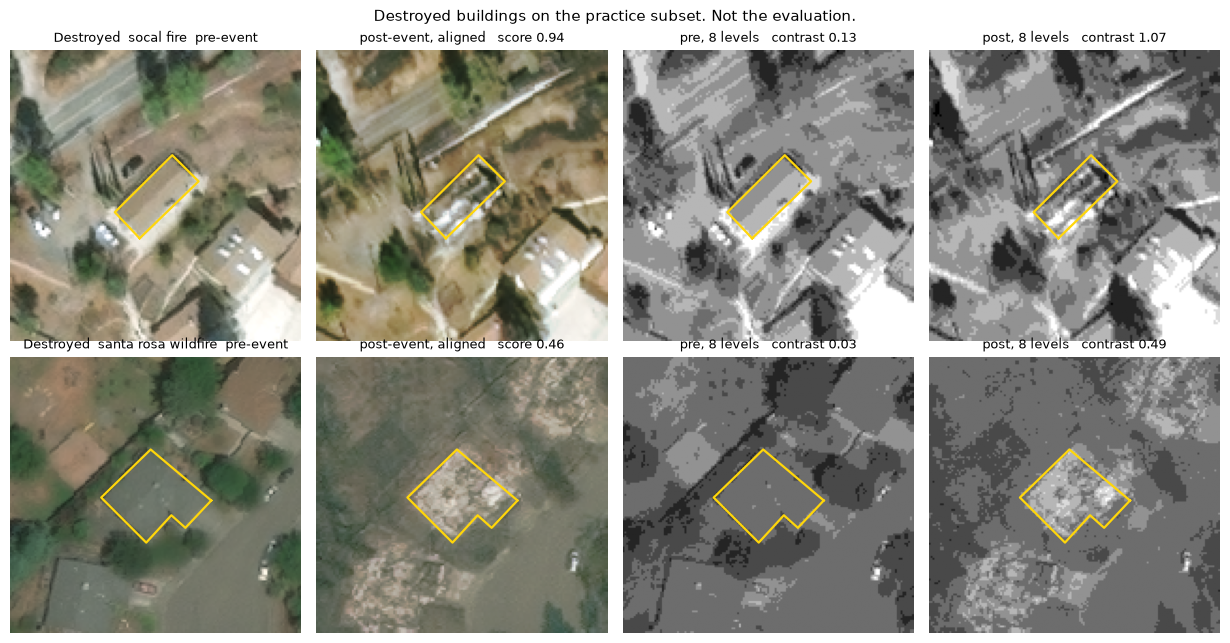

socal-fire_00000090 4234d824-6b36-4619-b4df-ad23a43b5bc1 0.936 545
santa-rosa-wildfire_00000007 38caa4f5-c7f2-44cd-85d6-22a998e94f6e 0.456 1289


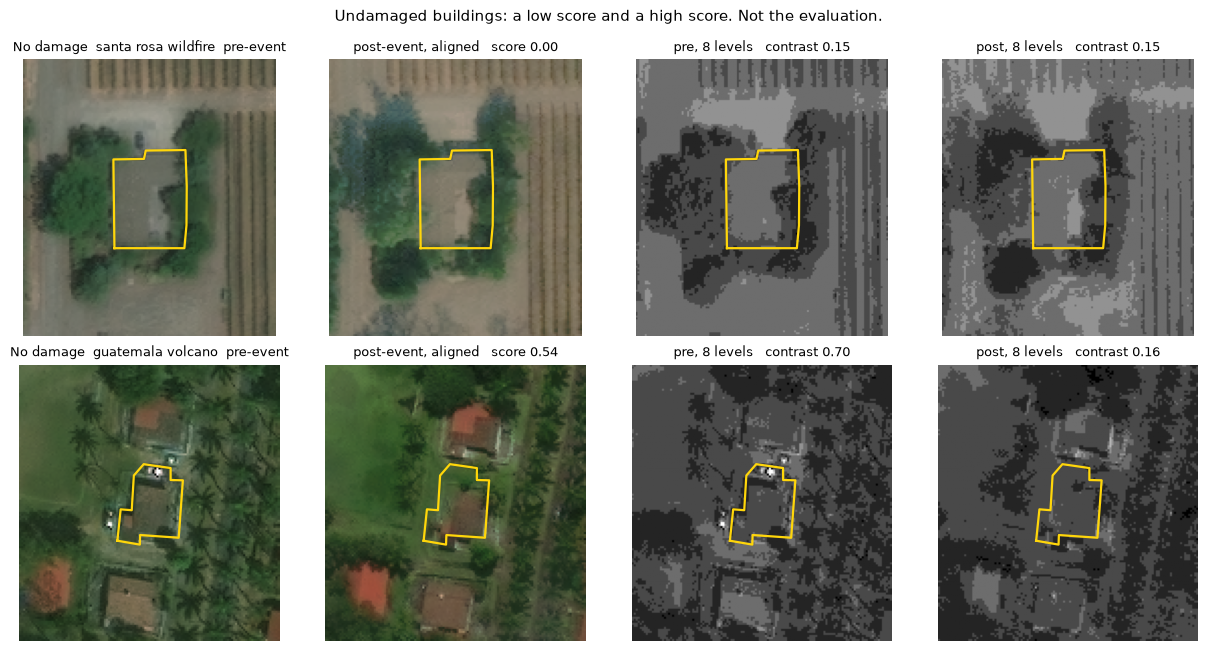

santa-rosa-wildfire_00000011 37e6f9a6-a7c3-4258-bc35-d43fc8fd8092 0.001 1918
guatemala-volcano_00000006 d4193ed2-cd81-4671-8b0b-6f205d8d30d4 0.538 840


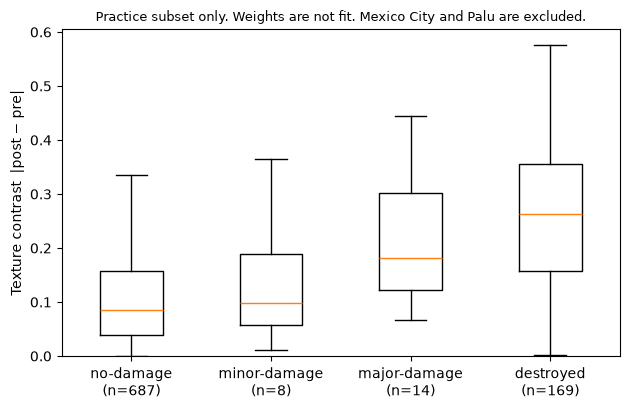

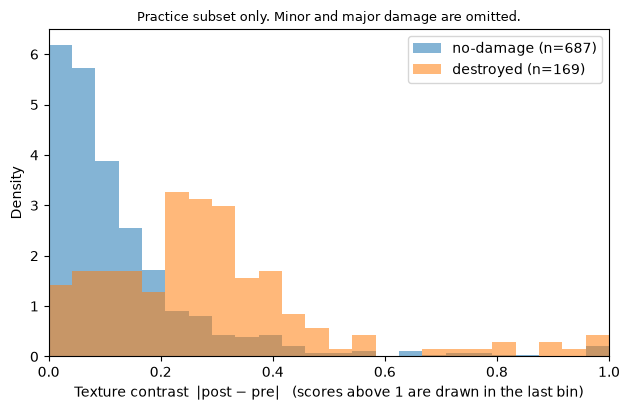

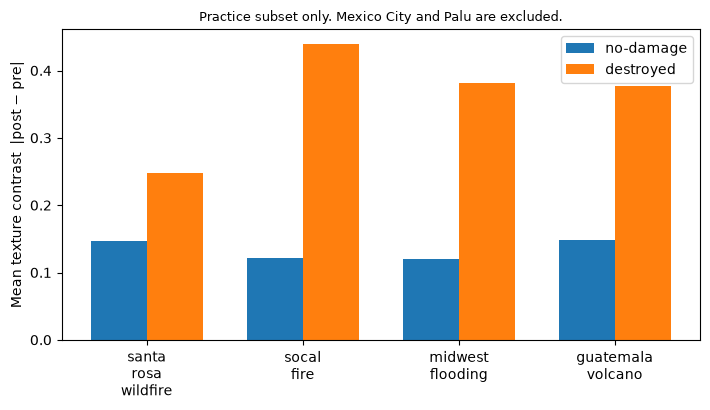

In [8]:
def crop_box(points, shape, margin=48):
    height, width = shape
    x0 = max(0, int(np.floor(points[:, 0].min())) - margin)
    y0 = max(0, int(np.floor(points[:, 1].min())) - margin)
    x1 = min(width, int(np.ceil(points[:, 0].max())) + margin)
    y1 = min(height, int(np.ceil(points[:, 1].max())) + margin)
    return x0, y0, x1, y1


def take_crop(image, box, dx=0, dy=0):
    x0, y0, x1, y1 = box
    height, width = image.shape[:2]
    src_x0 = min(max(x0 + dx, 0), width - 1)
    src_y0 = min(max(y0 + dy, 0), height - 1)
    src_x1 = min(max(x1 + dx, src_x0 + 1), width)
    src_y1 = min(max(y1 + dy, src_y0 + 1), height)
    crop = image[src_y0:src_y1, src_x0:src_x1]
    canvas = np.zeros((y1 - y0, x1 - x0) + image.shape[2:], dtype=image.dtype)
    dest_x = src_x0 - (x0 + dx)
    dest_y = src_y0 - (y0 + dy)
    canvas[dest_y:dest_y + crop.shape[0], dest_x:dest_x + crop.shape[1]] = crop
    return canvas


def draw_outline(axis, points, origin):
    relative = points - np.array(origin, dtype=np.float64)
    closed = np.vstack([relative, relative[:1]])
    axis.plot(closed[:, 0], closed[:, 1], color="#ffd60a", linewidth=1.6)
    axis.set_axis_off()


def event_name(image_id):
    return image_id.rsplit("_", 1)[0]


def panel_cases(cases, path, suptitle):
    fig, axes = plt.subplots(len(cases), 4, figsize=(12.4, 3.3 * len(cases)))
    if len(cases) == 1:
        axes = np.array([axes])
    cache = {}
    for axis_row, case in zip(axes, cases):
        if case["image_id"] not in cache:
            pre, post, _ = load_pair(case["image_id"])
            cache[case["image_id"]] = (pre, histogram_match(post, pre))
        pre, matched = cache[case["image_id"]]
        box = crop_box(case["points"], pre.shape[:2])
        pre_crop = take_crop(pre, box)
        post_crop = take_crop(matched, box, case["dx"], case["dy"])
        origin = (box[0], box[1])
        place = event_name(case["image_id"]).replace("-", " ")
        kind = "Destroyed" if case["subtype"] == "destroyed" else "No damage"
        axis_row[0].imshow(cv2.cvtColor(pre_crop, cv2.COLOR_BGR2RGB))
        axis_row[0].set_title(f"{kind}  {place}  pre-event", fontsize=9)
        axis_row[1].imshow(cv2.cvtColor(post_crop, cv2.COLOR_BGR2RGB))
        axis_row[1].set_title(f"post-event, aligned   score {case['score']:.2f}", fontsize=9)
        axis_row[2].imshow(quantize(luminance(pre_crop)), cmap="gray", vmin=0, vmax=LEVELS - 1)
        axis_row[2].set_title(f"pre, 8 levels   contrast {case['pre_contrast']:.2f}", fontsize=9)
        axis_row[3].imshow(quantize(luminance(post_crop)), cmap="gray", vmin=0, vmax=LEVELS - 1)
        axis_row[3].set_title(f"post, 8 levels   contrast {case['post_contrast']:.2f}", fontsize=9)
        for axis in axis_row:
            draw_outline(axis, case["points"], origin)
    fig.suptitle(suptitle, fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    for case in cases:
        print(case["image_id"], case["building_id"], f"{case['score']:.3f}", case["n_pixels"])


def visible_cases(subtype):
    pool = []
    for row in rows:
        if row["subtype"] != subtype or row["n_pixels"] < 250:
            continue
        points = row["points"]
        width = float(points[:, 0].max() - points[:, 0].min())
        height = float(points[:, 1].max() - points[:, 1].min())
        short = min(width, height)
        long = max(width, height)
        if short < 24 or long > 160 or long / short > 2.4:
            continue
        if points[:, 0].min() < 20 or points[:, 1].min() < 20:
            continue
        if points[:, 0].max() > 1004 or points[:, 1].max() > 1004:
            continue
        pool.append(row)
    return sorted(pool, key=lambda row: row["score"])


destroyed_pool = visible_cases("destroyed")
intact_pool = visible_cases("no-damage")
destroyed_high = destroyed_pool[-1]
destroyed_other = next(
    row for row in reversed(destroyed_pool)
    if event_name(row["image_id"]) != event_name(destroyed_high["image_id"])
)
panel_cases(
    [destroyed_high, destroyed_other],
    FIGURE_DIR / "examples_destroyed.png",
    "Destroyed buildings on the practice subset. Not the evaluation.",
)
panel_cases(
    [intact_pool[0], intact_pool[-1]],
    FIGURE_DIR / "examples_intact.png",
    "Undamaged buildings: a low score and a high score. Not the evaluation.",
)

class_order = ["no-damage", "minor-damage", "major-damage", "destroyed"]
class_scores = [
    [row["score"] for row in rows if row["subtype"] == name]
    for name in class_order
]
all_scores = np.array([row["score"] for row in rows], dtype=np.float64)
upper = float(np.ceil(np.percentile(all_scores, 99)))

fig, axis = plt.subplots(figsize=(6.4, 4.2))
axis.boxplot(class_scores, showfliers=False)
axis.set_xticks(
    range(1, len(class_order) + 1),
    [f"{name}\n(n={len(values)})" for name, values in zip(class_order, class_scores)],
)
axis.set_ylabel("Texture contrast  |post − pre|")
axis.set_ylim(bottom=0)
axis.set_title("Practice subset only. Weights are not fit. Mexico City and Palu are excluded.", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "score_by_class.png", dpi=160, bbox_inches="tight")
plt.show()

bins = np.linspace(0, upper, 25)
fig, axis = plt.subplots(figsize=(6.4, 4.2))
axis.hist(np.clip(class_scores[0], 0, upper), bins=bins, density=True, alpha=0.55, label=f"no-damage (n={len(class_scores[0])})")
axis.hist(np.clip(class_scores[3], 0, upper), bins=bins, density=True, alpha=0.55, label=f"destroyed (n={len(class_scores[3])})")
axis.set_xlabel(f"Texture contrast  |post − pre|   (scores above {upper:.0f} are drawn in the last bin)")
axis.set_ylabel("Density")
axis.set_xlim(0, upper)
axis.legend()
axis.set_title("Practice subset only. Minor and major damage are omitted.", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "score_histogram.png", dpi=160, bbox_inches="tight")
plt.show()

event_order = []
for image_id in SUBSET:
    event = event_name(image_id)
    if event not in event_order:
        event_order.append(event)
grouped = {}
for name in ("no-damage", "destroyed"):
    grouped[name] = []
    for event in event_order:
        values = np.array([
            row["score"]
            for row in rows
            if row["subtype"] == name and event_name(row["image_id"]) == event
        ])
        grouped[name].append(float(values.mean()) if values.size else np.nan)
positions = np.arange(len(event_order))
width = 0.36
fig, axis = plt.subplots(figsize=(7.2, 4.2))
axis.bar(positions - width / 2, grouped["no-damage"], width, label="no-damage")
axis.bar(positions + width / 2, grouped["destroyed"], width, label="destroyed")
axis.set_xticks(positions, [event.replace("-", "\n") for event in event_order])
axis.set_ylabel("Mean texture contrast  |post − pre|")
axis.legend()
axis.set_title("Practice subset only. Mexico City and Palu are excluded.", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "score_by_event.png", dpi=160, bbox_inches="tight")
plt.show()

## Partial numbers

A single threshold on the score turns it into a destroyed-versus-rest decision. The threshold is the value on a 0.01 grid with the highest destroyed-versus-rest F1 among those that keep the undamaged false-positive rate at or below 0.25. A false positive here is an undamaged building whose score is at least the threshold. The same cap is the one used later, when the five scores are weighted. This cut is provisional. It was fit on these 13 pairs only, and it will not be reused on Mexico City or Palu.

Precision, recall, and F1 use destroyed as the positive class and every other classified building as the negative class. Minor damage is too rare in this subset to support its own score. The threshold figure shows F1 and the undamaged false-positive rate across the range, with this cut marked.

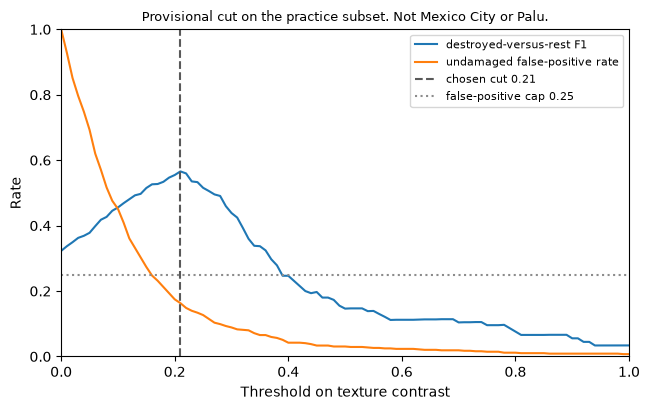

class, n, mean, median
no-damage, 687, 0.1323, 0.0843
minor-damage, 8, 0.1330, 0.0976
major-damage, 14, 0.2160, 0.1806
destroyed, 169, 0.2978, 0.2639
event, no-damage n, no-damage mean, destroyed n, destroyed mean
santa-rosa-wildfire, 208, 0.1461, 116, 0.2473
socal-fire, 61, 0.1219, 26, 0.4392
midwest-flooding, 321, 0.1204, 6, 0.3816
guatemala-volcano, 97, 0.1486, 21, 0.3773
threshold, 0.21, destroyed_f1, 0.5658, precision, 0.4872, recall, 0.6746
undamaged_false_positive_rate, 0.1630, tp, 114, fp, 120, fn, 55
subset is 13 practice pairs. This cut is not frozen and was not applied to Mexico City or Palu.


In [9]:
def binary_counts(y_true, y_pred):
    true_pos = int(np.sum(y_true & y_pred))
    false_pos = int(np.sum(~y_true & y_pred))
    false_neg = int(np.sum(y_true & ~y_pred))
    return true_pos, false_pos, false_neg


def f1_from_counts(true_pos, false_pos, false_neg):
    precision = true_pos / (true_pos + false_pos) if true_pos + false_pos else 0.0
    recall = true_pos / (true_pos + false_neg) if true_pos + false_neg else 0.0
    if precision + recall == 0:
        return 0.0, precision, recall
    return 2 * precision * recall / (precision + recall), precision, recall


scores = all_scores
destroyed = np.array([row["subtype"] == "destroyed" for row in rows])
undamaged = np.array([row["subtype"] == "no-damage" for row in rows])
thresholds = np.round(np.arange(0.0, float(np.ceil(scores.max())) + 0.001, 0.01), 2)
f1_curve = []
rate_curve = []
best = None
for cut in thresholds:
    predicted = scores >= cut
    undamaged_rate = float(predicted[undamaged].mean()) if undamaged.any() else 1.0
    true_pos, false_pos, false_neg = binary_counts(destroyed, predicted)
    f1_value, precision, recall = f1_from_counts(true_pos, false_pos, false_neg)
    f1_curve.append(f1_value)
    rate_curve.append(undamaged_rate)
    if undamaged_rate > 0.25:
        continue
    candidate = (f1_value, -undamaged_rate, cut, precision, recall, undamaged_rate, true_pos, false_pos, false_neg)
    if best is None or candidate > best:
        best = candidate

f1, _, threshold, precision, recall, undamaged_rate, true_pos, false_pos, false_neg = best

fig, axis = plt.subplots(figsize=(6.6, 4.2))
axis.plot(thresholds, f1_curve, label="destroyed-versus-rest F1")
axis.plot(thresholds, rate_curve, label="undamaged false-positive rate")
axis.axvline(threshold, color="0.35", linestyle="--", label=f"chosen cut {threshold:.2f}")
axis.axhline(0.25, color="0.55", linestyle=":", label="false-positive cap 0.25")
axis.set_xlim(0, upper)
axis.set_ylim(0, 1)
axis.set_xlabel("Threshold on texture contrast")
axis.set_ylabel("Rate")
axis.legend(fontsize=8)
axis.set_title("Provisional cut on the practice subset. Not Mexico City or Palu.", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "threshold_curve.png", dpi=160, bbox_inches="tight")
plt.show()

lines = ["class, n, mean, median"]
for name in class_order:
    values = scores[np.array([row["subtype"] == name for row in rows])]
    if values.size == 0:
        lines.append(f"{name}, 0, , ")
        continue
    lines.append(f"{name}, {values.size}, {values.mean():.4f}, {np.median(values):.4f}")
lines.append("event, no-damage n, no-damage mean, destroyed n, destroyed mean")
for event in event_order:
    no_damage_values = [
        row["score"] for row in rows
        if row["subtype"] == "no-damage" and event_name(row["image_id"]) == event
    ]
    destroyed_values = [
        row["score"] for row in rows
        if row["subtype"] == "destroyed" and event_name(row["image_id"]) == event
    ]
    no_mean = f"{np.mean(no_damage_values):.4f}" if no_damage_values else ""
    destroyed_mean = f"{np.mean(destroyed_values):.4f}" if destroyed_values else ""
    lines.append(
        f"{event}, {len(no_damage_values)}, {no_mean}, {len(destroyed_values)}, {destroyed_mean}"
    )
lines.append(
    f"threshold, {threshold:.2f}, destroyed_f1, {f1:.4f}, precision, {precision:.4f}, recall, {recall:.4f}"
)
lines.append(
    f"undamaged_false_positive_rate, {undamaged_rate:.4f}, tp, {true_pos}, fp, {false_pos}, fn, {false_neg}"
)
lines.append("subset is 13 practice pairs. This cut is not frozen and was not applied to Mexico City or Palu.")
metrics_path = TABLE_DIR / "texture_metrics.txt"
metrics_path.write_text("\n".join(lines) + "\n")
print("\n".join(lines))

## Buildings under 40 pixels

The shared preprocessing erodes each polygon by one pixel and falls back to the original polygon when fewer than 40 pixels survive. A co-occurrence matrix on so few pixels has few pairs, so the contrast of these buildings is noisy. Two counts are reported. The first is the number of buildings whose filled polygon is already under 40 pixels. The second is the number whose eroded interior is under 40 pixels, which is the number of buildings where the fallback was used. The first group is inside the second.

In [10]:
polygon_pixels = np.array([row["polygon_pixels"] for row in rows])
eroded_pixels = np.array([row["eroded_pixels"] for row in rows])
subtypes = np.array([row["subtype"] for row in rows])
small_polygon = polygon_pixels < 40
small_interior = eroded_pixels < 40

small_lines = [
    f"buildings scored, {len(rows)}",
    f"filled polygon under 40 pixels, {int(small_polygon.sum())}, {small_polygon.mean():.4f}",
    f"eroded interior under 40 pixels (original polygon used), {int(small_interior.sum())}, {small_interior.mean():.4f}",
    "class, n, polygon under 40, interior under 40",
]
for name in class_order:
    chosen = subtypes == name
    small_lines.append(
        f"{name}, {int(chosen.sum())}, {int((small_polygon & chosen).sum())}, {int((small_interior & chosen).sum())}"
    )
small_lines.append("event, n, polygon under 40, interior under 40")
events = np.array([event_name(row["image_id"]) for row in rows])
for event in event_order:
    chosen = events == event
    small_lines.append(
        f"{event}, {int(chosen.sum())}, {int((small_polygon & chosen).sum())}, {int((small_interior & chosen).sum())}"
    )
small_lines.append(
    f"median score, interior under 40, {np.median(scores[small_interior]):.4f}, "
    f"interior 40 or more, {np.median(scores[~small_interior]):.4f}"
)
(TABLE_DIR / "small_buildings.txt").write_text("\n".join(small_lines) + "\n")
print("\n".join(small_lines))

buildings scored, 878
filled polygon under 40 pixels, 4, 0.0046
eroded interior under 40 pixels (original polygon used), 16, 0.0182
class, n, polygon under 40, interior under 40
no-damage, 687, 3, 11
minor-damage, 8, 0, 0
major-damage, 14, 0, 0
destroyed, 169, 1, 5
event, n, polygon under 40, interior under 40
santa-rosa-wildfire, 333, 2, 4
socal-fire, 88, 0, 2
midwest-flooding, 333, 1, 4
guatemala-volcano, 124, 1, 6
median score, interior under 40, 0.6213, interior 40 or more, 0.1053


## The square-meter area formula

The final report compares the predicted and the reference damaged area in square meters, so pixel areas have to be converted. The check is done on two images from the subset at different latitudes: `santa-rosa-wildfire_00000006` (about 38.5° N) and `guatemala-volcano_00000006` (about 14.4° N).

The pixel area of a polygon is the shoelace formula on its `xy` vertices,

\[
A_{\text{px}} = \tfrac{1}{2}\left|\sum_k (x_k y_{k+1} - x_{k+1} y_k)\right| ,
\]

which adds the signed areas of the triangles formed by the origin and each edge of the polygon. The formula under test is \(A_{\text{m}^2} = A_{\text{px}} \cdot p\), where \(p\) is the ground area of one pixel of that image in square meters. The question is where \(p\) comes from. Four candidates are compared.

1. **Label fit.** The label file stores every polygon twice: in pixels (`features.xy`) and in longitude and latitude (`features.lng_lat`). Every vertex is therefore a control point, and the affine map from pixels to the ground is estimated by least squares, as in image registration with control points in the point-processing lecture (and Q4 of the sample exam, which uses exactly three points). \(p\) is the absolute determinant of the 2 by 2 linear part of that map: the area, in square meters, of the image of a 1 by 1 pixel square.
2. **Geotransform file.** `xview_geotransforms.json` gives one pixel size in degrees for both directions. \(p\) is that size squared, in meters.
3. **`gsd` squared**, from the label metadata.
4. **`pan_resolution` squared**, from the label metadata.

Degrees become meters on a spherical Earth of radius \(R = 6371\) km. One degree of latitude is an arc of \(\pi R / 180 \approx 111.2\) km. A circle of latitude \(\varphi\) has radius \(R\cos\varphi\), so one degree of longitude is shorter by \(\cos\varphi\):

\[
m_{\text{lat}} = \frac{\pi R}{180}, \qquad
m_{\text{lon}} = \frac{\pi R}{180}\cos\varphi .
\]

The Earth is slightly flattened. On these two images the exact ellipsoid would change the area of a pixel by less than 0.4%, far below the 30% and 50% area-error targets, so the sphere is enough.

The reference does not use the pixel coordinates. Each `lng_lat` polygon is turned into meters with \(m_{\text{lon}}\) and \(m_{\text{lat}}\) at its own mean latitude, and the shoelace formula is applied to those vertices. The filled-pixel count of each polygon is also compared with its shoelace area.

In [11]:
EARTH_RADIUS_M = 6371000.0


def meters_per_degree(latitude):
    lat_m = np.pi * EARTH_RADIUS_M / 180.0
    lon_m = lat_m * np.cos(np.radians(latitude))
    return lon_m, lat_m


def shoelace(points):
    x = points[:, 0]
    y = points[:, 1]
    return 0.5 * abs(float(np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)))


def lng_lat_area(points):
    lon_m, lat_m = meters_per_degree(float(points[:, 1].mean()))
    metric = np.column_stack([points[:, 0] * lon_m, points[:, 1] * lat_m])
    return shoelace(metric - metric.mean(axis=0))


def fit_pixel_to_ground(pixel_points, geographic_points):
    # Least-squares affine map from pixel (x, y) to meters east and north of the mean vertex.
    lon_m, lat_m = meters_per_degree(float(geographic_points[:, 1].mean()))
    east = (geographic_points[:, 0] - geographic_points[:, 0].mean()) * lon_m
    north = (geographic_points[:, 1] - geographic_points[:, 1].mean()) * lat_m
    design = np.column_stack([pixel_points, np.ones(len(pixel_points))])
    east_fit = np.linalg.lstsq(design, east, rcond=None)[0]
    north_fit = np.linalg.lstsq(design, north, rcond=None)[0]
    residual = np.hypot(design @ east_fit - east, design @ north_fit - north).max()
    jacobian = np.array([east_fit[:2], north_fit[:2]])
    side_x = float(np.hypot(jacobian[0, 0], jacobian[1, 0]))
    side_y = float(np.hypot(jacobian[0, 1], jacobian[1, 1]))
    rotation = float(np.degrees(np.arctan2(jacobian[1, 0], jacobian[0, 0])))
    return abs(float(np.linalg.det(jacobian))), side_x, side_y, rotation, float(residual)


GEOTRANSFORM_PATH = DATA_ROOT.parent / "xview_geotransforms.json"
geotransforms = json.loads(GEOTRANSFORM_PATH.read_text())

AREA_IMAGES = ["santa-rosa-wildfire_00000006", "guatemala-volcano_00000006"]
area_rows = []
area_lines = []
for image_id in AREA_IMAGES:
    label = json.loads((LABEL_DIR / f"{image_id}_post_disaster.json").read_text())
    geographic = {
        feature["properties"]["uid"]: polygon_points(feature["wkt"])
        for feature in label["features"]["lng_lat"]
    }
    buildings = []
    for feature in label["features"]["xy"]:
        if feature["properties"]["subtype"] == "un-classified":
            continue
        uid = feature["properties"]["uid"]
        buildings.append((uid, polygon_points(feature["wkt"]), geographic[uid]))

    all_pixel = np.vstack([pixel for _, pixel, _ in buildings])
    all_geographic = np.vstack([ground for _, _, ground in buildings])
    fit_area, side_x, side_y, rotation, residual = fit_pixel_to_ground(all_pixel, all_geographic)

    transform = geotransforms[f"{image_id}_post_disaster.png"][0]
    assert transform == geotransforms[f"{image_id}_pre_disaster.png"][0]
    center_latitude = transform[3] + transform[5] * label["metadata"]["height"] / 2.0
    lon_m, lat_m = meters_per_degree(center_latitude)
    file_w = abs(transform[1]) * lon_m
    file_h = abs(transform[5]) * lat_m
    gsd = label["metadata"]["gsd"]
    pan = label["metadata"]["pan_resolution"]
    pixel_area = {
        "label fit": fit_area,
        "geotransform file": file_w * file_h,
        "gsd squared": gsd * gsd,
        "pan_resolution squared": pan * pan,
    }

    per_building = []
    for uid, pixel, ground in buildings:
        area_px = shoelace(pixel)
        filled_px = int(polygon_mask(pixel, (1024, 1024)).sum())
        reference_m2 = lng_lat_area(ground)
        per_building.append((area_px, filled_px, reference_m2))
        area_rows.append({
            "image_id": image_id,
            "building_id": uid,
            "shoelace_px": f"{area_px:.2f}",
            "filled_px": filled_px,
            "lng_lat_m2": f"{reference_m2:.2f}",
            "label_fit_m2": f"{area_px * pixel_area['label fit']:.2f}",
            "geotransform_m2": f"{area_px * pixel_area['geotransform file']:.2f}",
            "gsd_squared_m2": f"{area_px * pixel_area['gsd squared']:.2f}",
            "pan_squared_m2": f"{area_px * pixel_area['pan_resolution squared']:.2f}",
        })
    table = np.array(per_building)
    total_px, total_filled, total_reference = table.sum(axis=0)
    area_lines += [
        f"{image_id}",
        f"  buildings, {len(table)}, center latitude, {center_latitude:.4f}",
        f"  label fit: pixel side along x m, {side_x:.4f}, along y m, {side_y:.4f}, rotation deg, {rotation:.3f}, worst vertex residual m, {residual:.4f}",
        f"  geotransform file: pixel width m, {file_w:.4f}, pixel height m, {file_h:.4f}",
        f"  metadata: gsd, {gsd:.4f}, pan_resolution, {pan:.4f}",
        f"  total shoelace px, {total_px:.1f}, total filled px, {total_filled:.0f}, filled over shoelace, {total_filled / total_px:.4f}",
        f"  total lng_lat reference m2, {total_reference:.1f}",
        "  source of pixel area, pixel area m2, total m2, total over reference, worst building over reference",
    ]
    for name, value in pixel_area.items():
        ratios = table[:, 0] * value / table[:, 2]
        worst = ratios[np.argmax(np.abs(ratios - 1.0))]
        area_lines.append(
            f"  {name}, {value:.4f}, {total_px * value:.1f}, {total_px * value / total_reference:.4f}, {worst:.4f}"
        )

with (TABLE_DIR / "area_check.csv").open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=list(area_rows[0]))
    writer.writeheader()
    writer.writerows(area_rows)
(TABLE_DIR / "area_check.txt").write_text("\n".join(area_lines) + "\n")
print("\n".join(area_lines))

santa-rosa-wildfire_00000006
  buildings, 38, center latitude, 38.4939
  label fit: pixel side along x m, 0.4471, along y m, 0.4489, rotation deg, -0.157, worst vertex residual m, 0.0041
  geotransform file: pixel width m, 0.4018, pixel height m, 0.5134
  metadata: gsd, 1.8770, pan_resolution, 0.4689
  total shoelace px, 141617.0, total filled px, 145607, filled over shoelace, 1.0282
  total lng_lat reference m2, 28419.7
  source of pixel area, pixel area m2, total m2, total over reference, worst building over reference
  label fit, 0.2007, 28419.7, 1.0000, 1.0000
  geotransform file, 0.2063, 29211.0, 1.0278, 1.0278
  gsd squared, 3.5231, 498931.8, 17.5558, 17.5559
  pan_resolution squared, 0.2198, 31134.0, 1.0955, 1.0955
guatemala-volcano_00000006
  buildings, 97, center latitude, 14.3665
  label fit: pixel side along x m, 0.4897, along y m, 0.4928, rotation deg, -0.548, worst vertex residual m, 0.0022
  geotransform file: pixel width m, 0.4834, pixel height m, 0.4990
  metadata: gsd,

### Reading the check

The label fit is an affine map with a worst vertex residual of a few millimeters. Its pixel sides are 0.447 m by 0.449 m on the Santa Rosa image and 0.490 m by 0.493 m on the Guatemala image, with a rotation under one degree. The two sides differ by less than 1%, which is about the size of the spherical-Earth approximation, so one number per image is enough, and \(A_{\text{m}^2} = A_{\text{px}} \cdot p\) reproduces the `lng_lat` areas building by building. That agreement is by construction for the label fit. What the check adds is that the map from pixels to the ground is affine, so a single \(p\) holds over the whole image.

The geotransform file is an independent source. It agrees with the labels to 0.02% on the Guatemala image and is 2.8% high on the Santa Rosa image, the same ratio for every building in the image. The file states one pixel size in degrees for both directions, which is not a square on the ground away from the equator, so it is used as a cross-check and not as the source of \(p\).

The two metadata shortcuts fail. `gsd` squared overstates the area about 17.6 times on Santa Rosa and 8.2 times on Guatemala: the `gsd` field is the multispectral resolution, about four times the pixel side of these PNGs. `pan_resolution` squared is 10% high on one image and 49% low on the other. Because those factors change from image to image, they would not cancel in an area error pooled over many images.

The filled-pixel count is 3% and 10% above the shoelace area on these two images, because the raster fill keeps the boundary pixels. The gap is larger where buildings are small. The area is therefore taken from the shoelace formula on the original polygon vertices, not from a pixel count.

The formula carried to the final report is \(A_{\text{m}^2} = A_{\text{px}} \cdot p\), with \(A_{\text{px}}\) from the shoelace formula on the un-eroded polygon and \(p\) from the label fit of that image. This was checked on two practice images only.

## What this run is, and what is left

The CSV, the example panels, the charts, the count of small buildings, and the area check are the progress material for texture contrast. They live under `outputs/texture_contrast/progress/`. The class means should be read with the subset in mind: most destroyed buildings here are fire losses, and minor damage has only a handful of polygons.

Still open for this score: the same CSV on the remaining practice pairs, written later under `outputs/texture_contrast/final/`. Once the grades exist, the damaged area is computed from the original, un-eroded polygons with the formula checked above, and compared with the ground-truth area on Palu and on the pooled evaluation. Those cities are not in `SUBSET`, and nothing in this notebook is a reason to change the formula after they are seen.